In [22]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import sys
import os
module_dir = (Path.cwd() / ".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))

import validation as val
import importlib

importlib.reload(val)  # pick up edits in validation.py without restarting the kernel



<module 'validation' from '/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/algorithms/validation.py'>

In [23]:
start_time = "1998-12-01 00:00:00"
end_time = "1999-02-28 23:59:59"
REGION = (-80, 20, 30, 80)   # smaller region for tracking, limited by the domain, 10 deg smaller
DOMAIN = (-90, 30, 20, 90)   # tracking domain (region + buffer), limited by the downloaded data

data_set = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=start_time, end_time=end_time)

In [24]:
data_set

,lon,lat,vorticity,mslp_lon,mslp_lat,mslp,track_id,time
obs,,,,,,,,
0,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00
1,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00
2,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00
3,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00
4,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00
...,...,...,...,...,...,...,...,...
8523,174.133652,85.109848,3.723335,NaN,NaN,1024.317,2562,1999-02-26 12:00:00
8524,161.192886,84.471527,3.298671,NaN,NaN,1028.030,2562,1999-02-26 18:00:00
8525,150.237457,83.856377,2.820443,NaN,NaN,1031.977,2562,1999-02-27 00:00:00


In [25]:
filtered, summary = val.postprocess_validation_tracks(data_set, region=REGION, domain=DOMAIN, time_range=(start_time, end_time))

In [26]:
filtered

,lon,lat,vorticity,mslp_lon,mslp_lat,mslp,track_id,time,step_km,in_region,at_edge
obs,,,,,,,,,,,
0,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00,0.000000,True,False
1,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00,244.913948,True,False
2,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00,721.918965,True,False
3,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00,265.968187,True,False
4,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00,175.433700,True,False
...,...,...,...,...,...,...,...,...,...,...,...
8493,-7.907135,34.614578,4.372137,353.6227,35.20124,1010.945,2526,1999-02-27 18:00:00,270.788053,True,False
8494,-7.607819,30.702158,3.782341,354.5373,29.72373,1007.276,2526,1999-02-28 00:00:00,435.941928,True,False
8495,-5.629944,27.143463,3.748619,355.5177,28.63590,1008.591,2526,1999-02-28 06:00:00,440.019750,False,False


In [27]:
summary

,track_id,n_points,start_time,end_time,lat_genesis,lon_genesis,lat_lysis,lon_lysis,path_km,n_in_region,...,lat_peak,lon_peak,peak_in_region,starts_at_first_frame,ends_at_last_frame,ok_region,ok_edge,ok_peak,ok_time,keep
0,3,8,1998-12-01 00:00:00,1998-12-02 18:00:00,45.558174,0.487187,32.335617,-6.001343,1953.201698,8,...,34.762379,-8.886871,True,True,False,True,True,True,True,True
1,7,23,1998-12-01 00:00:00,1998-12-06 12:00:00,41.390289,-39.932556,55.724674,-54.287354,3725.046847,23,...,45.770313,-36.278229,True,True,False,True,True,True,True,True
2,8,28,1998-12-01 00:00:00,1998-12-07 18:00:00,60.707550,-43.543549,54.875725,21.990213,4317.915690,26,...,65.186493,-22.897980,True,True,False,True,True,True,True,True
3,11,23,1998-12-01 00:00:00,1998-12-06 12:00:00,45.816334,-82.061401,65.929779,-95.633392,4586.956321,9,...,50.607555,-68.742401,True,True,False,True,True,True,True,True
4,20,21,1998-12-01 00:00:00,1998-12-06 00:00:00,72.899658,52.011211,81.876442,169.238129,3366.638753,0,...,73.467667,58.283115,False,True,False,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
462,2521,9,1999-02-26 18:00:00,1999-02-28 18:00:00,72.440567,16.541874,85.188438,-22.369354,1657.250012,5,...,72.440567,16.541874,True,False,False,True,True,True,True,True
463,2524,9,1999-02-26 18:00:00,1999-02-28 18:00:00,5.650308,63.212944,7.471993,53.195278,1180.296156,0,...,6.281818,55.973289,False,False,False,False,False,True,True,False
464,2526,8,1999-02-27 00:00:00,1999-02-28 18:00:00,39.186470,-10.691101,24.450230,-2.642365,1941.799741,5,...,37.043434,-8.124786,True,False,False,True,True,True,True,True
465,2559,14,1999-02-21 18:00:00,1999-02-25 00:00:00,31.636181,60.047581,28.794010,78.987732,2083.723805,0,...,28.358469,69.499413,False,False,False,False,False,True,True,False


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


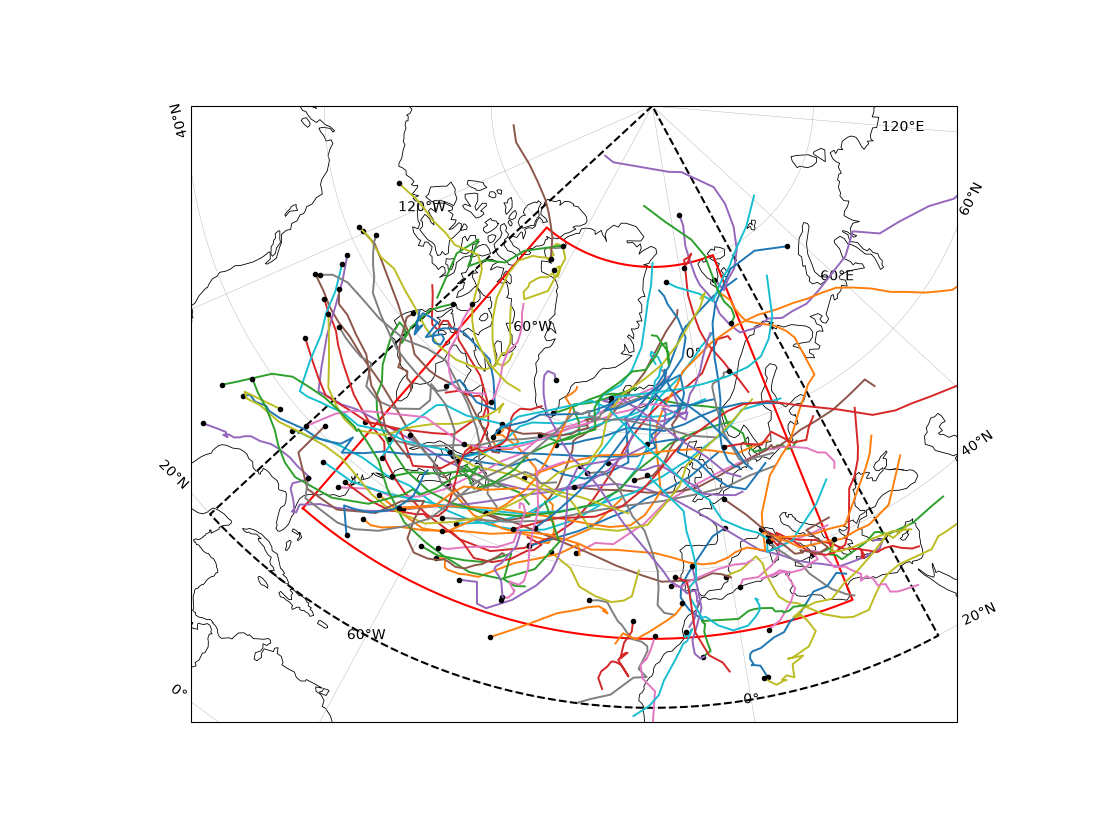

In [28]:
ax = val.plot_regional_tracks(filtered, region=REGION, domain=DOMAIN, summary = summary, object=False)